# Micro-Project 4: Predicting Vulnerability Severity with Deep Learning Regression

**ANA500 -- Data Science Process**

- **Author:** Christian Cruz
- **Scope:** This notebook covers the full data science process, from **Acquire** through
**Act**, using deep learning regression (a feed-forward neural network and a recurrent
neural network, the LSTM) built with TensorFlow/Keras. It uses the same CVE data source as
Micro-Projects 1 to 3 and compares every neural network against the Micro-Project 3
regression models with the **same baseline and the same evaluation metrics**.

## Problem Statement
Security teams face a constantly growing volume of publicly disclosed vulnerabilities
(CVEs) and must decide which to patch first. Teams usually sort by the official CVSS
severity score, but that score comes from a detailed technical analysis that takes time.
When a CVE is first published, a team often has to decide what to look at first before
that analysis is finished.

Micro-Project 3 showed that basic descriptive facts about a CVE (vendor, product, weakness
type, publication year, and number of affected products) can estimate its severity better
than guessing. Two questions remain about how useful that is in practice:

1. **Does it hold up on new CVEs?** Micro-Project 3 tested on a random sample of CVEs from
   all years, so the models were partly tested on the past. A team would use the model on
   CVEs published *after* the model was trained.
2. **Does it work on the day a CVE is published?** Almost every CVE still waiting for a
   score has no weakness type (CWE) assigned yet, and the weakness type was Micro-Project
   3's most informative input. Every CVE, however, is published with a written
   description from day one.

## Hypothesis Formulation
A deep learning model, specifically a **recurrent neural network (LSTM) that reads each
CVE's written description**, will estimate the CVSS v3.x score of **newly published CVEs**
more accurately than Micro-Project 3's regression models, and will keep working when the
weakness type is not yet known.

**Test:** train every model on older CVEs and test on the newest 25%. Using Micro-Project
3's baseline (always guess the average) and metrics (MAE, RMSE, R-squared, and training vs.
test R-squared), the LSTM should have a lower error than Ridge regression and SVR. As a
control, a plain neural network given only the same five facts as Micro-Project 3 shows
whether added model complexity by itself helps, without the description text.

## Step 1: Acquire

**Data source:** [`fkie-cad/nvd-json-data-feeds`](https://github.com/fkie-cad/nvd-json-data-feeds),
a community-maintained reconstruction of NIST's National Vulnerability Database (NVD) bulk
JSON feeds, rebuilt from the official NVD API 2.0 and refreshed every two hours. This is the
same source, the same twelve-year window (2015 to 2026), and the same extractor used in
Micro-Projects 1 to 3. Because the feed is live, record counts are slightly higher than in
Micro-Project 3; the cleaning logic is unchanged.

In [1]:
# ---- Standard library ----
import os
import re            # regular expressions, used to clean the description text
import lzma          # the yearly archives are .xz-compressed JSON
import json
import time
import urllib.request
from pathlib import Path

# Quiet TensorFlow's start-up log messages (must be set before TensorFlow is imported)
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

# ---- Data handling ----
import numpy as np
import pandas as pd

# ---- Charts (same Matplotlib style system as Micro-Projects 2 and 3) ----
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# ---- Machine learning (scikit-learn): preprocessing, Micro-Project 3 models, metrics ----
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             confusion_matrix, precision_recall_fscore_support)

# ---- Deep learning (TensorFlow / Keras) ----
import tensorflow as tf
import keras
from keras import layers

# Reproducibility: the same fixed random seed as Micro-Project 3. keras.utils.set_random_seed
# seeds Python, NumPy and TensorFlow together, so the neural networks start from the same
# random weights on every run.
RANDOM_STATE = 42
keras.utils.set_random_seed(RANDOM_STATE)

plt.rcParams["figure.autolayout"] = True
os.makedirs("figures", exist_ok=True)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

TensorFlow 2.21.0 | Keras 3.15.1


In [2]:
# Download the twelve yearly CVE archives (2015-2026), skipping any already on disk.
DATA_DIR = Path("data/raw")
DATA_DIR.mkdir(parents=True, exist_ok=True)

YEARS = list(range(2015, 2027))
BASE_URL = "https://github.com/fkie-cad/nvd-json-data-feeds/releases/latest/download"

for year in YEARS:
    fname = f"CVE-{year}.json.xz"
    target = DATA_DIR / fname
    if target.exists():
        print(f"{fname}: already downloaded, skipping")
        continue
    print(f"{fname}: downloading ...")
    urllib.request.urlretrieve(f"{BASE_URL}/{fname}", target)

print("\nAll yearly CVE archives present in", DATA_DIR)

CVE-2015.json.xz: already downloaded, skipping
CVE-2016.json.xz: already downloaded, skipping
CVE-2017.json.xz: already downloaded, skipping
CVE-2018.json.xz: already downloaded, skipping
CVE-2019.json.xz: already downloaded, skipping
CVE-2020.json.xz: already downloaded, skipping
CVE-2021.json.xz: already downloaded, skipping
CVE-2022.json.xz: already downloaded, skipping
CVE-2023.json.xz: already downloaded, skipping
CVE-2024.json.xz: already downloaded, skipping
CVE-2025.json.xz: already downloaded, skipping
CVE-2026.json.xz: already downloaded, skipping

All yearly CVE archives present in data/raw


## Step 2: Prepare

### 2.1 Flatten the nested JSON (same extractor as Micro-Projects 1 to 3)

Each CVE record is turned into one flat row. The extractor is unchanged. The only
difference in this project is how the output is used: Micro-Project 3 kept the English
description in the dataset but did not use it as a model input. This project uses it.

In [3]:
def first_metric(metric_list):
    """A CVE can carry several scores for the same CVSS version (e.g. one from NVD and
    one from the vendor). Prefer the one NVD marked 'Primary'; otherwise take the first."""
    if not metric_list:
        return None
    for m in metric_list:
        if m.get("type") == "Primary":
            return m
    return metric_list[0]


def extract_row(item):
    """Flatten one raw CVE record into a dictionary (one future table row)."""
    row = {
        "cve_id": item.get("id"),
        "published_date": item.get("published"),
        "vuln_status": item.get("vulnStatus"),
    }

    # English description text (used as a model input in this project, see 2.5)
    row["description_en"] = next(
        (d.get("value") for d in item.get("descriptions", []) if d.get("lang") == "en"), None)

    # Vendor / product: take the first listed, and count how many products are affected
    vendors, products = [], []
    for src in item.get("affected", []):
        for ad in src.get("affectedData", []):
            if ad.get("vendor"):
                vendors.append(ad["vendor"])
            if ad.get("product"):
                products.append(ad["product"])
    row["primary_vendor"] = vendors[0] if vendors else None
    row["primary_product"] = products[0] if products else None
    row["num_affected_products"] = len(products)

    # Weakness type (CWE), e.g. CWE-79 = cross-site scripting
    row["cwe_id"] = None
    weaknesses = item.get("weaknesses", [])
    if weaknesses:
        row["cwe_id"] = next((d.get("value") for d in weaknesses[0].get("description", [])
                              if d.get("lang") == "en"), None)

    metrics = item.get("metrics", {})

    # CVSS v2 (oldest standard): only the score is needed here
    v2 = first_metric(metrics.get("cvssMetricV2"))
    row["v2_score"] = v2["cvssData"].get("baseScore") if v2 else None

    # CVSS v3.x (v3.1 preferred over v3.0): the score is our prediction TARGET.
    # The attack vector and the two sub-scores are pulled out only to demonstrate
    # leakage in section 2.4; they are never used as model inputs.
    v3 = first_metric(metrics.get("cvssMetricV31")) or first_metric(metrics.get("cvssMetricV30"))
    row["v3_version"] = row["v3_score"] = row["v3_attack_vector"] = None
    row["v3_exploitability_score"] = row["v3_impact_score"] = None
    if v3:
        cd = v3.get("cvssData", {})
        row["v3_version"] = cd.get("version")
        row["v3_score"] = cd.get("baseScore")
        row["v3_attack_vector"] = cd.get("attackVector")
        row["v3_exploitability_score"] = v3.get("exploitabilityScore")
        row["v3_impact_score"] = v3.get("impactScore")

    # CVSS v4.0 (newest standard): only the score is needed here
    v4 = first_metric(metrics.get("cvssMetricV40"))
    row["v4_score"] = v4["cvssData"].get("baseScore") if v4 else None
    return row


# Parse every yearly archive into one list of rows, then one DataFrame.
records = []
for year in YEARS:
    with lzma.open(DATA_DIR / f"CVE-{year}.json.xz") as f:
        data = json.load(f)
    records.extend(extract_row(item) for item in data["cve_items"])
    print(f"CVE-{year}: {len(data['cve_items']):,} records")

df_raw = pd.DataFrame.from_records(records)
print(f"\nTotal records flattened: {len(df_raw):,}")

CVE-2015: 8,780 records


CVE-2016: 10,649 records


CVE-2017: 17,108 records


CVE-2018: 17,817 records


CVE-2019: 17,625 records


...

CVE-2023: 31,451 records


CVE-2024: 39,257 records


CVE-2025: 45,347 records


CVE-2026: 69,876 records



Total records flattened: 330,013


### 2.2 Clean the main dataset (same rules as Micro-Project 3)

1. Convert the literal `"n/a"` vendor/product placeholder into a real missing value.
2. Drop withdrawn (`Rejected`) CVE IDs.
3. Keep CVEs that have no score yet in the main dataset (they are used again in Step 5).
4. Parse dates and derive the publication year.

In [4]:
df = df_raw.copy()

# 1. Placeholder text -> real missing value
for col in ["primary_vendor", "primary_product"]:
    is_placeholder = df[col].astype(str).str.strip().str.lower().isin(["", "n/a", "none", "nan"])
    df.loc[is_placeholder, col] = np.nan

# 2. Drop withdrawn CVE IDs
n_rejected = (df["vuln_status"] == "Rejected").sum()
df = df[df["vuln_status"] != "Rejected"].copy()

# 4. Dates
df["published_date"] = pd.to_datetime(df["published_date"], errors="coerce")
df["published_year"] = df["published_date"].dt.year

# A record is "scored" if it has a CVSS score under ANY version
df["has_any_score"] = df[["v2_score", "v3_score", "v4_score"]].notna().any(axis=1)

print(f"Raw records:                    {len(df_raw):,}")
print(f"Dropped as Rejected (withdrawn): {n_rejected:,}")
print(f"Main cleaned dataset:           {len(df):,} records")
print(f"  ...of which still unscored:   {(~df['has_any_score']).sum():,} (kept)")
print("\nVendor missing:  {:.1%}".format(df["primary_vendor"].isna().mean()))
print("Product missing: {:.1%}".format(df["primary_product"].isna().mean()))

# 3. Save the main cleaned dataset, unscored records included.
df.to_pickle("data/cve_clean_mp4.pkl")

Raw records:                    330,013
Dropped as Rejected (withdrawn): 15,462
Main cleaned dataset:           314,551 records
  ...of which still unscored:   3,378 (kept)

Vendor missing:  29.2%
Product missing: 24.0%


### 2.3 Build the modeling subset: CVSS v3.x scores only

Same rule as Micro-Project 3: the prediction target is the CVSS v3.0/v3.1 score, because
those two versions share one scale and one set of severity bands. CVEs with no score, or
scored only under v2 or v4.0, stay in the main dataset but are left out of modeling.

In [5]:
has_v3 = df["v3_score"].notna()
unscored = ~df["has_any_score"]
other_version_only = df["has_any_score"] & ~has_v3

summary = pd.DataFrame({
    "Records": [len(df), unscored.sum(), other_version_only.sum(), has_v3.sum()],
}, index=["Main cleaned dataset",
          "  minus: no score yet",
          "  minus: scored only under v2 or v4.0",
          "= Modeling subset (CVSS v3.x)"])
print(summary.to_string(formatters={"Records": "{:,}".format}))

model_df = df[has_v3].copy()
model_df["v3_score"] = model_df["v3_score"].astype(float)
print("\nv3 version mix in modeling subset:")
print(model_df["v3_version"].value_counts().to_string())

                                      Records
Main cleaned dataset                  314,551
  minus: no score yet                   3,378
  minus: scored only under v2 or v4.0  12,434
= Modeling subset (CVSS v3.x)         298,739



v3 version mix in modeling subset:
v3_version
3.1    256413
3.0     42326


### 2.4 The five descriptive facts (same inputs as Micro-Project 3)

The score's own ingredients (attack vector, exploitability and impact sub-scores) are still
excluded, because Micro-Project 3 showed they reproduce the score's formula (R-squared
0.986) rather than predict it. The five descriptive facts are unchanged, with missing
values labeled `"Unknown"`.

In [6]:
CAT_FEATURES = ["primary_vendor", "primary_product", "cwe_id"]
NUM_FEATURES = ["published_year", "num_affected_products"]
TARGET = "v3_score"

for col in CAT_FEATURES:
    model_df[col] = model_df[col].fillna("Unknown")

# How many distinct values does each category have? This matters for encoding (3.2).
for col in CAT_FEATURES:
    print(f"{col:18s} {model_df[col].nunique():>7,} distinct values")

primary_vendor      24,163 distinct values
primary_product     54,309 distinct values
cwe_id                 768 distinct values


### 2.5 The new input: the written description, and a leakage check

Every CVE is published with a short written description, for example *"SQL injection in the
login page of Product X allows remote attackers to read the database."* It is available on
day one, even when the weakness type is not. Typical descriptions are short (about 40
words).

**Leakage check.** Micro-Project 3 removed inputs that already contain the answer. The
description needs the same check: some vendors paste the CVSS score itself into the
description (for example *"CVSS 3.1 Base Score 7.5"* followed by the full scoring vector).
Leaving that in would let the model read the answer instead of estimating it. The cell below
counts these cases and removes every sentence that mentions CVSS, a base score, or a CVSS
vector string. The rest of the description is kept.

In [7]:
# Split a description into sentences (a sentence ends with . ! or ? followed by a space).
SENTENCE_SPLIT = re.compile(r"(?<=[.!?])\s+")
# A sentence is removed if it mentions CVSS, a "base score", or a CVSS vector such as "AV:N/".
SCORE_TEXT = re.compile(r"cvss|base score|AV:[NALP]/", re.IGNORECASE)


def clean_description(text):
    """Remove any sentence that states the CVSS score, keep everything else."""
    if not isinstance(text, str):
        return ""
    return " ".join(s for s in SENTENCE_SPLIT.split(text) if not SCORE_TEXT.search(s))


has_score_text = model_df["description_en"].fillna("").str.contains(SCORE_TEXT)
print(f"Descriptions that state a CVSS score or vector: {has_score_text.sum():,} "
      f"({has_score_text.mean():.1%} of the modeling subset)")

model_df["text"] = model_df["description_en"].map(clean_description)
print(f"After cleaning, descriptions still mentioning CVSS: "
      f"{model_df['text'].str.contains(SCORE_TEXT).sum():,}")

# Show one example before and after cleaning.
example = model_df.loc[has_score_text].iloc[0]
print("\nBEFORE:", example["description_en"][-330:])
print("\nAFTER: ", example["text"][-330:])

words = model_df["text"].str.split().str.len()
print(f"\nDescription length (words): median {words.median():.0f}, "
      f"90% of descriptions are {words.quantile(0.9):.0f} words or fewer")

Descriptions that state a CVSS score or vector: 8,379 (2.8% of the modeling subset)


After cleaning, descriptions still mentioning CVSS: 0

BEFORE: VMware Tools prior to 10.0.9 contains multiple file system races in libDeployPkg, related to the use of hard-coded paths under /tmp. Successful exploitation of this issue may result in a local privilege escalation. CVSS:3.0/AV:L/AC:H/PR:L/UI:R/S:U/C:H/I:H/A:H

AFTER:  VMware Tools prior to 10.0.9 contains multiple file system races in libDeployPkg, related to the use of hard-coded paths under /tmp. Successful exploitation of this issue may result in a local privilege escalation.



Description length (words): median 41, 90% of descriptions are 95 words or fewer


### 2.6 Two ways to split the data into training and test sets

**Split A: Micro-Project 3's random split (continuity check).** The exact same settings
(75/25, `random_state=42`). Re-running Micro-Project 3's models on this split confirms the
pipeline reproduces its results, so later differences come from the split, not from a
coding change.

**Split B: chronological split (the main test in this project).** CVEs are sorted by
publication date. The oldest 75% become the training set and the newest 25% become the test
set. Every test CVE was published after every training CVE, which is how the model would be
used in practice: trained on what has already happened, then applied to what comes next.
The 75/25 proportion is kept the same as Micro-Project 3 so the two splits differ only in
*which* CVEs are held out.

In [8]:
# Sort by publication date (CVE ID breaks ties) so "older" and "newer" are well defined.
model_df = model_df.sort_values(["published_date", "cve_id"]).reset_index(drop=True)
X_all = model_df[CAT_FEATURES + NUM_FEATURES]
y_all = model_df[TARGET].astype("float32")

# ---- Split A: Micro-Project 3's random split ----
idx_train_A, idx_test_A = train_test_split(model_df.index, test_size=0.25,
                                           random_state=RANDOM_STATE)

# ---- Split B: chronological split, oldest 75% train / newest 25% test ----
cut = int(len(model_df) * 0.75)
idx_train_B, idx_test_B = model_df.index[:cut], model_df.index[cut:]
cutoff_date = model_df.loc[cut, "published_date"]


def severity_band(score):
    """CVSS v3 qualitative bands (0.0 'None' grouped with LOW, as in Micro-Project 3)."""
    return pd.cut(score, bins=[-0.1, 3.95, 6.95, 8.95, 10.0], labels=SEVERITY_ORDER)


SEVERITY_ORDER = ["LOW", "MEDIUM", "HIGH", "CRITICAL"]
for name, tr, te in [("A: random", idx_train_A, idx_test_A),
                     ("B: chronological", idx_train_B, idx_test_B)]:
    print(f"Split {name}: {len(tr):,} training / {len(te):,} test CVEs")

d = model_df["published_date"]
print(f"\nChronological training CVEs: published {d[idx_train_B].min():%Y-%m-%d} to "
      f"{d[idx_train_B].max():%Y-%m-%d}")
print(f"Chronological test CVEs:     published {d[idx_test_B].min():%Y-%m-%d} to "
      f"{d[idx_test_B].max():%Y-%m-%d}")

mix = pd.DataFrame({
    "B train": severity_band(y_all[idx_train_B]).value_counts(normalize=True),
    "B test":  severity_band(y_all[idx_test_B]).value_counts(normalize=True),
}).reindex(SEVERITY_ORDER).mul(100).round(1)
print("\nShare of each severity band in the chronological split (%):")
print(mix.to_string())
print(f"\nAverage score: training {y_all[idx_train_B].mean():.2f}, test {y_all[idx_test_B].mean():.2f}")

Split A: random: 224,054 training / 74,685 test CVEs
Split B: chronological: 224,054 training / 74,685 test CVEs

Chronological training CVEs: published 2015-01-13 to 2025-11-17
Chronological test CVEs:     published 2025-11-17 to 2026-10-09

Share of each severity band in the chronological split (%):
          B train  B test
v3_score                 
LOW           2.0     3.3
MEDIUM       43.8    40.5
HIGH         39.8    43.2
CRITICAL     14.4    13.0

Average score: training 7.08, test 7.03


**Reading this output:** the chronological test set covers roughly the last year of CVEs.
Its severity mix and average score are close to the training set, so any drop in accuracy
on this split is not because new CVEs are simply more or less severe on average. It comes
from new CVEs being *different* in other ways: new vendors and products, and new
combinations the models have not seen.

**A validation slice for the neural networks.** Neural networks train in repeated passes
over the data (called *epochs*) and can start memorizing the training data if they run for
too long. To decide when to stop, 10% of the training set is held back as a **validation
set**, and training stops when the error on it stops improving (*early stopping*). The test
set is never used for this decision. On the chronological split the validation slice is the
*most recent* 10% of the training period, so even this check looks forward in time.

In [9]:
def validation_slice(train_idx, chronological):
    """Hold back 10% of the training rows for early stopping (never the test rows)."""
    if chronological:
        n_val = int(len(train_idx) * 0.10)
        return train_idx[:-n_val], train_idx[-n_val:]      # newest 10% of the training period
    return train_test_split(train_idx, test_size=0.10, random_state=RANDOM_STATE)


fit_A, val_A = validation_slice(idx_train_A, chronological=False)
fit_B, val_B = validation_slice(idx_train_B, chronological=True)
print(f"Split A: {len(fit_A):,} rows to learn from, {len(val_A):,} validation rows")
print(f"Split B: {len(fit_B):,} rows to learn from, {len(val_B):,} validation rows "
      f"(published {d[val_B].min():%Y-%m-%d} to {d[val_B].max():%Y-%m-%d})")

Split A: 201,648 rows to learn from, 22,406 validation rows
Split B: 201,649 rows to learn from, 22,405 validation rows (published 2025-05-13 to 2025-11-17)


### 2.7 Turning inputs into numbers

**The five facts** use the exact preprocessing from Micro-Project 3 (one-hot encoding with
values seen fewer than 50 times grouped as "infrequent", a log transform of the skewed
product count, and standardization). Neural networks need a regular (dense) table of
numbers, so the encoded result is converted from scikit-learn's compressed (sparse) format.

**The description text** is converted by Keras' `TextVectorization` layer:
1. It builds a vocabulary of the 20,000 most common words in the training descriptions.
2. Each description becomes a list of word ID numbers (for example "sql" might be word 812).
3. Every list is cut or padded to exactly 100 words, which covers about 90% of descriptions
   in full. Padding uses the ID 0, which the LSTM is told to ignore.

The vocabulary is learned from the training rows only, the same rule as every other
preprocessing step, so the test descriptions are never peeked at.

In [10]:
def make_preprocessor():
    """Micro-Project 3's preprocessing for the five facts, unchanged."""
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50),
         CAT_FEATURES),
        ("num", Pipeline([
            ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
            ("scaler", StandardScaler()),
        ]), NUM_FEATURES),
    ])


def to_dense(prep, rows):
    """Encode the five facts for the given rows and return a dense float32 array."""
    return prep.transform(X_all.loc[rows]).toarray().astype("float32")


VOCAB_SIZE, SEQ_LEN = 20_000, 100


def make_vectorizer(train_rows):
    """Learn the word vocabulary from the training descriptions only."""
    vec = layers.TextVectorization(max_tokens=VOCAB_SIZE, output_sequence_length=SEQ_LEN)
    vec.adapt(tf.data.Dataset.from_tensor_slices(model_df.loc[train_rows, "text"].values).batch(4096))
    return vec


# Small demonstration of what the LSTM actually receives.
demo_vec = make_vectorizer(fit_B[:20_000])
demo_text = model_df.loc[fit_B[0], "text"]
print("Description:", demo_text[:160], "...")
print("As word IDs:", demo_vec([demo_text]).numpy()[0][:20], "...")

Description: Directory traversal vulnerability in the TS WebProxy (aka TSWbPrxy) component in Microsoft Windows Vista SP2, Windows 7 SP1, Windows Server 2008 R2 SP1, Windows ...
As word IDs: [  174   321     9     4     3  7674 16918    48 18287    62     4    64
    21   477   154    21   190   119    21    36] ...


## Step 3: Analyze Data

### 3.1 How the models are graded (same as Micro-Project 3)

- **Baseline:** always guess the average training score. Every model must beat it.
- **MAE:** on average, how many CVSS points the prediction misses by.
- **RMSE:** like MAE, but large misses count extra.
- **R-squared:** share of the variation in scores the model explains (0 = no better than
  the baseline, 1 = perfect).
- **Training R-squared vs. test R-squared:** a large gap signals a model that fits its
  training data much better than new data.

Following up on Micro-Project 3's finding that the models under-rate CRITICAL CVEs, each
model is also graded as a **severity classifier** in section 3.8: its predicted score is
turned into a LOW / MEDIUM / HIGH / CRITICAL band and compared with the true band.

In [11]:
results = []   # one row per model and split, collected for the comparison tables
preds = {}     # test-set predictions, kept for the charts and the Act step


def evaluate(name, split, y_tr, p_tr, y_te, p_te, train_rows, seconds):
    """Grade a model with Micro-Project 3's metrics and store its test predictions."""
    row = {
        "Split": split, "Model": name, "Trained on": f"{train_rows:,} rows",
        "Test MAE": mean_absolute_error(y_te, p_te),
        "Test RMSE": mean_squared_error(y_te, p_te) ** 0.5,
        "Test R2": r2_score(y_te, p_te),
        "Train R2": r2_score(y_tr, p_tr),
        "Train time (s)": round(seconds),
    }
    row["Gap (Train R2 - Test R2)"] = row["Train R2"] - row["Test R2"]
    results.append(row)
    preds[(split, name)] = np.asarray(p_te, dtype="float32")
    print(f"[{split}] {name}: test MAE {row['Test MAE']:.3f} | RMSE {row['Test RMSE']:.3f} | "
          f"test R2 {row['Test R2']:.3f} | train R2 {row['Train R2']:.3f} ({seconds:.0f}s)")


def run_mp3_models(split, train_idx, test_idx, include_svr):
    """Baseline, Ridge and (optionally) SVR, exactly as built in Micro-Project 3."""
    X_tr, y_tr = X_all.loc[train_idx], y_all[train_idx]
    X_te, y_te = X_all.loc[test_idx], y_all[test_idx]

    # Baseline: always guess the average training score
    avg = y_tr.mean()
    evaluate("Baseline (guess average)", split, y_tr, np.full(len(y_tr), avg),
             y_te, np.full(len(y_te), avg), len(y_tr), 0)

    # Ridge regression with Micro-Project 3's tuned penalty (alpha = 0.1), all training rows
    t0 = time.time()
    ridge = Pipeline([("prep", make_preprocessor()), ("model", Ridge(alpha=0.1))])
    ridge.fit(X_tr, y_tr)
    evaluate("Ridge (MP3)", split, y_tr, ridge.predict(X_tr), y_te, ridge.predict(X_te),
             len(y_tr), time.time() - t0)

    if include_svr:
        # RBF SVR with Micro-Project 3's tuned settings, on a 30,000-row training sample
        t0 = time.time()
        s_idx = X_tr.sample(30_000, random_state=RANDOM_STATE).index
        svr = Pipeline([("prep", make_preprocessor()),
                        ("model", SVR(kernel="rbf", C=1, gamma="scale", epsilon=0.25,
                                      cache_size=2000))])
        svr.fit(X_tr.loc[s_idx], y_tr[s_idx])
        evaluate("SVR (MP3, 30k sample)", split, y_tr[s_idx], svr.predict(X_tr.loc[s_idx]),
                 y_te, svr.predict(X_te), 30_000, time.time() - t0)
    return ridge

### 3.2 The first neural network: a feed-forward network (MLP) on the five facts

**Intuition:** a *multilayer perceptron* (MLP) is the basic neural network. Each layer takes
weighted sums of the numbers coming in and passes them through a simple bend (ReLU: keep
positive values, set negative ones to zero). Stacking layers lets the network learn
combinations that a straight line cannot, for example "this weakness type is only severe
for this kind of product." It gets exactly the same 700-plus encoded columns as Ridge
regression, so any difference comes from the model, not the inputs.

Settings, with the reasons:
- Two hidden layers (256 and 64 units), then one output unit for the predicted score.
- **Dropout (20%)** randomly switches off units during training so the network cannot rely
  on any single path, a standard guard against overfitting.
- **Loss = mean squared error**, the same quantity linear regression minimizes, so the two
  are optimizing the same goal. The Adam optimizer adjusts the weights.
- **Early stopping** (section 2.6): stop when validation error has not improved for 2
  epochs and keep the best weights.

In [12]:
def build_mlp(n_inputs):
    """Feed-forward network: inputs -> 256 -> dropout -> 64 -> 1 predicted score."""
    model = keras.Sequential([
        keras.Input(shape=(n_inputs,)),
        layers.Dense(256, activation="relu"),
        layers.Dropout(0.2),
        layers.Dense(64, activation="relu"),
        layers.Dense(1),                       # one number out: the predicted CVSS score
    ])
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse", metrics=["mae"])
    return model


def early_stop():
    """Stop when validation loss stops improving for 2 epochs; keep the best weights."""
    return [keras.callbacks.EarlyStopping(monitor="val_loss", patience=2,
                                          restore_best_weights=True)]


histories = {}   # training curves, charted in section 3.7


def run_mlp(split, fit_idx, val_idx, test_idx):
    """Fit the preprocessing on the learning rows, train the MLP, and grade it."""
    prep = make_preprocessor().fit(X_all.loc[fit_idx])
    T_fit, T_val, T_te = to_dense(prep, fit_idx), to_dense(prep, val_idx), to_dense(prep, test_idx)
    y_fit, y_val, y_te = y_all[fit_idx].values, y_all[val_idx].values, y_all[test_idx].values

    keras.utils.set_random_seed(RANDOM_STATE)
    mlp = build_mlp(T_fit.shape[1])
    t0 = time.time()
    hist = mlp.fit(T_fit, y_fit, validation_data=(T_val, y_val), epochs=30,
                   batch_size=512, callbacks=early_stop(), verbose=0)
    secs = time.time() - t0
    histories[(split, "MLP")] = hist.history
    print(f"MLP stopped after {len(hist.history['loss'])} epochs")
    evaluate("Neural network (MLP), 5 facts", split,
             y_fit, mlp.predict(T_fit, batch_size=4096, verbose=0).ravel(),
             y_te, mlp.predict(T_te, batch_size=4096, verbose=0).ravel(), len(fit_idx), secs)
    return mlp, prep

### 3.3 Continuity check: Micro-Project 3's random split (Split A)

Before changing the test design, the baseline, Ridge, and the new MLP are run on
Micro-Project 3's own random split. Ridge should land very close to Micro-Project 3's
reported result (MAE 1.10, R-squared 0.31).

In [13]:
ridge_A = run_mp3_models("A: random", idx_train_A, idx_test_A, include_svr=False)
mlp_A, prep_A = run_mlp("A: random", fit_A, val_A, idx_test_A)
del mlp_A, prep_A      # free memory; only the predictions are needed from here on

[A: random] Baseline (guess average): test MAE 1.423 | RMSE 1.697 | test R2 -0.000 | train R2 0.000 (0s)


[A: random] Ridge (MP3): test MAE 1.102 | RMSE 1.412 | test R2 0.308 | train R2 0.315 (4s)


MLP stopped after 20 epochs


[A: random] Neural network (MLP), 5 facts: test MAE 1.030 | RMSE 1.355 | test R2 0.362 | train R2 0.403 (91s)


**Reading this output:** Ridge reproduces Micro-Project 3 (about 1.10 MAE and 0.31
R-squared), so the pipeline is unchanged. On this random split the MLP is clearly better
than Ridge. The next step checks whether that advantage survives on CVEs from the future.

### 3.4 The main test: chronological split (Split B), Micro-Project 3's models and the MLP

In [14]:
ridge_B = run_mp3_models("B: chronological", idx_train_B, idx_test_B, include_svr=True)
mlp_B, prep_B = run_mlp("B: chronological", fit_B, val_B, idx_test_B)

[B: chronological] Baseline (guess average): test MAE 1.402 | RMSE 1.705 | test R2 -0.001 | train R2 0.000 (0s)


[B: chronological] Ridge (MP3): test MAE 1.274 | RMSE 1.602 | test R2 0.117 | train R2 0.348 (4s)


[B: chronological] SVR (MP3, 30k sample): test MAE 1.218 | RMSE 1.576 | test R2 0.145 | train R2 0.365 (109s)


MLP stopped after 15 epochs


[B: chronological] Neural network (MLP), 5 facts: test MAE 1.259 | RMSE 1.599 | test R2 0.120 | train R2 0.413 (65s)


**Reading this output:** every model loses accuracy on newer CVEs. Ridge's R-squared falls
from about 0.31 on the random split to about 0.12, and its training-vs-test gap jumps from
almost nothing to more than 0.2. The gap on the random split was tiny, so this is not
ordinary memorization: patterns learned from older CVEs (especially specific vendors and
products) carry over less well to new ones. The MLP's advantage over Ridge also almost
disappears, so the extra flexibility mostly helped with vendor and product combinations it
had already seen.

### 3.5 The recurrent neural network: an LSTM that reads the description

**Intuition:** a *recurrent* neural network reads a sequence one step at a time, carrying a
running memory of what it has read so far, much like a person reading a sentence word by
word. An **LSTM** (Long Short-Term Memory) is a recurrent network with built-in "gates" that
decide what to remember and what to forget, so a word early in the description (for example
"unauthenticated") can still matter at the end. Recurrent networks are usually taught on
time series, such as one value per month. A description is also a sequence, of words
instead of months, and it is the input this project needs: it exists on day one.

Layers, in order:
1. **Embedding (64 numbers per word):** learns a numeric meaning for each vocabulary word, so
   that words used in similar ways (for example "execute" and "injection") end up close
   together. `mask_zero=True` tells the network to skip the padding.
2. **LSTM (64 units):** reads the description word by word and summarizes it as 64 numbers.
3. Dropout (20%), a small dense layer, and one output unit for the predicted score.

Training uses the same loss, optimizer, validation slice, and early stopping as the MLP.
This is the slowest model in the project (several minutes per epoch on a laptop-class CPU).

In [15]:
vec_B = make_vectorizer(fit_B)
S_fit, S_val, S_te = (vec_B(model_df.loc[i, "text"].values).numpy() for i in (fit_B, val_B, idx_test_B))
y_fit_B, y_val_B, y_te_B = y_all[fit_B].values, y_all[val_B].values, y_all[idx_test_B].values
print("Text input shape (rows, words):", S_fit.shape)

keras.utils.set_random_seed(RANDOM_STATE)
text_in = keras.Input(shape=(SEQ_LEN,), dtype="int64", name="description")
x = layers.Embedding(VOCAB_SIZE, 64, mask_zero=True)(text_in)   # word IDs -> word meanings
x = layers.LSTM(64)(x)                                          # read the words in order
x = layers.Dropout(0.2)(x)
x = layers.Dense(32, activation="relu")(x)
lstm = keras.Model(text_in, layers.Dense(1)(x), name="lstm_text")
lstm.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse", metrics=["mae"])
lstm.summary()

t0 = time.time()
hist = lstm.fit(S_fit, y_fit_B, validation_data=(S_val, y_val_B), epochs=8, batch_size=256,
                callbacks=early_stop(), verbose=2)
secs = time.time() - t0
histories[("B: chronological", "LSTM")] = hist.history
evaluate("LSTM, description text", "B: chronological",
         y_fit_B, lstm.predict(S_fit, batch_size=2048, verbose=0).ravel(),
         y_te_B, lstm.predict(S_te, batch_size=2048, verbose=0).ravel(), len(fit_B), secs)

Text input shape (rows, words): (201649, 100)


Model: "lstm_text"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ description         │ (None, 100)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 100, 64)   │  1,280,000 │ description[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 100)       │          0 │ description[0][0] │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 64)        │     33,024 │ embedding[0][0],  │
│                     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 64)        │          0 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 32)        │      2,080 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 1)         │         33 │ dense_6[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,315,137 (5.02 MB)

 Trainable params: 1,315,137 (5.02 MB)

...

Epoch 3/8


788/788 - 111s - 141ms/step - loss: 1.3769 - mae: 0.8893 - val_loss: 1.7982 - val_mae: 1.0146


Epoch 4/8


788/788 - 110s - 140ms/step - loss: 1.2561 - mae: 0.8418 - val_loss: 1.7880 - val_mae: 0.9990


[B: chronological] LSTM, description text: test MAE 1.146 | RMSE 1.475 | test R2 0.251 | train R2 0.571 (513s)


### 3.6 Combining both: LSTM on the description plus the five facts

The last model has **two inputs**. The description goes through the same embedding and LSTM
as above; the five encoded facts go through a dense layer of 128 units. The two summaries
are joined side by side (concatenated) and passed through a final dense layer to one
predicted score. This lets the network use the weakness type and vendor when they are known
and lean on the text when they are not.

In [16]:
T_fit_B, T_val_B, T_te_B = (to_dense(prep_B, i) for i in (fit_B, val_B, idx_test_B))

keras.utils.set_random_seed(RANDOM_STATE)
text_in = keras.Input(shape=(SEQ_LEN,), dtype="int64", name="description")
t = layers.Embedding(VOCAB_SIZE, 64, mask_zero=True)(text_in)
t = layers.LSTM(64)(t)                                          # text branch
facts_in = keras.Input(shape=(T_fit_B.shape[1],), name="five_facts")
f = layers.Dense(128, activation="relu")(facts_in)              # facts branch
z = layers.Concatenate()([t, f])                                # join the two summaries
z = layers.Dropout(0.2)(z)
z = layers.Dense(64, activation="relu")(z)
combined = keras.Model([text_in, facts_in], layers.Dense(1)(z), name="lstm_plus_facts")
combined.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse", metrics=["mae"])

t0 = time.time()
hist = combined.fit([S_fit, T_fit_B], y_fit_B, validation_data=([S_val, T_val_B], y_val_B),
                    epochs=8, batch_size=256, callbacks=early_stop(), verbose=2)
secs = time.time() - t0
histories[("B: chronological", "LSTM + facts")] = hist.history
evaluate("LSTM + 5 facts (combined)", "B: chronological",
         y_fit_B, combined.predict([S_fit, T_fit_B], batch_size=2048, verbose=0).ravel(),
         y_te_B, combined.predict([S_te, T_te_B], batch_size=2048, verbose=0).ravel(),
         len(fit_B), secs)

Epoch 1/8


788/788 - 114s - 145ms/step - loss: 2.7261 - mae: 1.1950 - val_loss: 1.7641 - val_mae: 0.9989


Epoch 2/8


788/788 - 140s - 178ms/step - loss: 1.4374 - mae: 0.9104 - val_loss: 1.6599 - val_mae: 0.9647


Epoch 3/8


...

Epoch 4/8


788/788 - 143s - 181ms/step - loss: 1.1579 - mae: 0.8023 - val_loss: 1.6385 - val_mae: 0.9491


Epoch 5/8


788/788 - 113s - 144ms/step - loss: 1.0674 - mae: 0.7643 - val_loss: 1.6491 - val_mae: 0.9469


[B: chronological] LSTM + 5 facts (combined): test MAE 1.114 | RMSE 1.437 | test R2 0.289 | train R2 0.629 (683s)


### 3.7 Model comparison

In [17]:
results_df = pd.DataFrame(results)
# Printed as two narrower tables so they fit on a page.
print(results_df[["Split", "Model", "Test MAE", "Test RMSE", "Test R2", "Train R2"]]
      .round(3).to_string(index=False))
print()
print(results_df[["Split", "Model", "Trained on", "Train time (s)", "Gap (Train R2 - Test R2)"]]
      .round(2).to_string(index=False))
results_df.round(4).to_csv("figures/mp4_results.csv", index=False)

chron = results_df[results_df["Split"] == "B: chronological"].set_index("Model")
base_mae = chron.loc["Baseline (guess average)", "Test MAE"]
ridge_mae = chron.loc["Ridge (MP3)", "Test MAE"]
print("\nChronological split, compared with the baseline and with Ridge (MP3):")
for name in chron.index[1:]:
    mae = chron.loc[name, "Test MAE"]
    print(f"  {name:32s} {1 - mae / base_mae:5.0%} below baseline | "
          f"{1 - mae / ridge_mae:5.0%} below Ridge")

           Split                         Model  Test MAE  Test RMSE  Test R2  Train R2
       A: random      Baseline (guess average)     1.423      1.697   -0.000     0.000
       A: random                   Ridge (MP3)     1.102      1.412    0.308     0.315
       A: random Neural network (MLP), 5 facts     1.030      1.355    0.362     0.403
B: chronological      Baseline (guess average)     1.402      1.705   -0.001     0.000
B: chronological                   Ridge (MP3)     1.274      1.602    0.117     0.348
B: chronological         SVR (MP3, 30k sample)     1.218      1.576    0.145     0.365
B: chronological Neural network (MLP), 5 facts     1.259      1.599    0.120     0.413
B: chronological        LSTM, description text     1.146      1.475    0.251     0.571
B: chronological     LSTM + 5 facts (combined)     1.114      1.437    0.289     0.629

           Split                         Model   Trained on  Train time (s)  Gap (Train R2 - Test R2)
       A: random      Basel

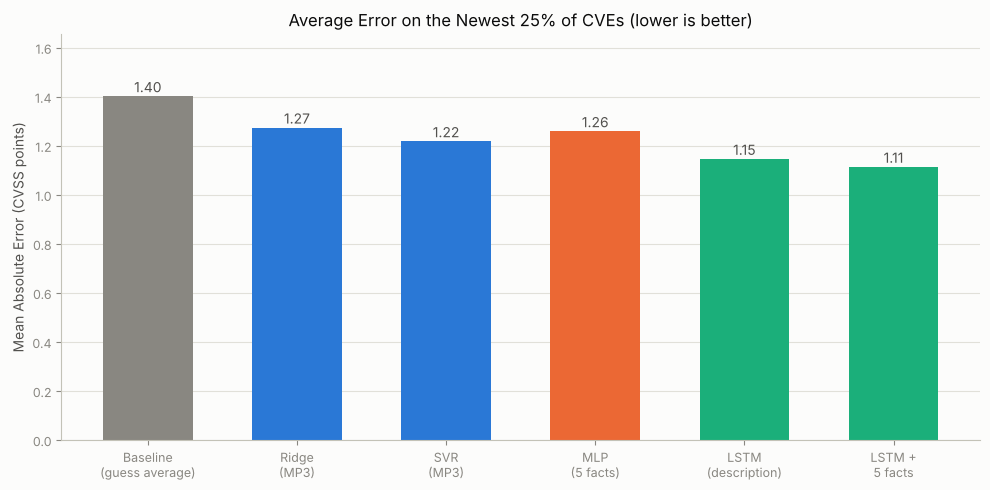

In [18]:
# Shared chart style from Micro-Projects 2 and 3, so every figure in the portfolio matches.
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
STATUS = {"LOW": "#0ca30c", "MEDIUM": "#fab219", "HIGH": "#ec835a", "CRITICAL": "#d03b3b"}
SURFACE, INK_PRIMARY, INK_SECONDARY, INK_MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRIDLINE, AXIS_LINE = "#e1e0d9", "#c3c2b7"


def style_ax(ax, y_grid=True, x_grid=False):
    """Apply the shared look (background, spines, grid, tick colors) to an axis."""
    ax.set_facecolor(SURFACE)
    ax.figure.set_facecolor(SURFACE)
    for name, spine in ax.spines.items():
        if name in ("top", "right"):
            spine.set_visible(False)
        else:
            spine.set_color(AXIS_LINE)
            spine.set_linewidth(0.8)
    ax.tick_params(colors=INK_MUTED, labelsize=9)
    ax.xaxis.label.set_color(INK_SECONDARY)
    ax.yaxis.label.set_color(INK_SECONDARY)
    ax.title.set_color(INK_PRIMARY)
    if y_grid:
        ax.grid(axis="y", color=GRIDLINE, linewidth=0.8, zorder=0)
    if x_grid:
        ax.grid(axis="x", color=GRIDLINE, linewidth=0.8, zorder=0)
    ax.set_axisbelow(True)
    return ax


# Chart 1: test MAE on the chronological split. Grey = baseline, blue = Micro-Project 3
# models, orange = neural network on the same facts, green = models that read the text.
order = ["Baseline (guess average)", "Ridge (MP3)", "SVR (MP3, 30k sample)",
         "Neural network (MLP), 5 facts", "LSTM, description text", "LSTM + 5 facts (combined)"]
labels = ["Baseline\n(guess average)", "Ridge\n(MP3)", "SVR\n(MP3)", "MLP\n(5 facts)",
          "LSTM\n(description)", "LSTM +\n5 facts"]
colors = [INK_MUTED, CAT[0], CAT[0], CAT[1], CAT[2], CAT[2]]
vals = chron.loc[order, "Test MAE"].values

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(labels, vals, color=colors, width=0.6)
for b, v in zip(bars, vals):
    ax.annotate(f"{v:.2f}", (b.get_x() + b.get_width() / 2, v), xytext=(0, 3),
                textcoords="offset points", ha="center", fontsize=10, color=INK_SECONDARY)
ax.set_title("Average Error on the Newest 25% of CVEs (lower is better)")
ax.set_ylabel("Mean Absolute Error (CVSS points)")
ax.set_ylim(0, max(vals) * 1.18)
style_ax(ax)
fig.savefig("figures/mae_chronological.png", dpi=200, facecolor=SURFACE)
plt.show()

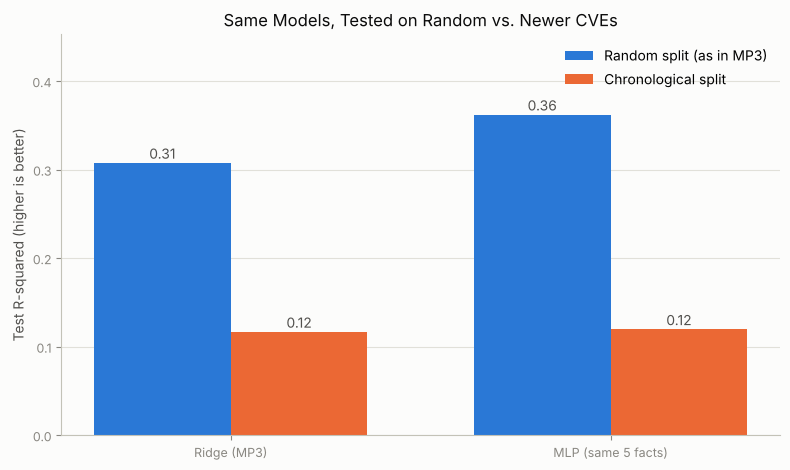

In [19]:
# Chart 2: R-squared for the same models on the random split (A) vs. the chronological
# split (B). Shows how much of Micro-Project 3's result depended on testing on the past.
both = results_df.pivot(index="Model", columns="Split", values="Test R2")
show = ["Ridge (MP3)", "Neural network (MLP), 5 facts"]
x = np.arange(len(show)); w = 0.36
fig, ax = plt.subplots(figsize=(8, 4.8))
for k, (split, color, lab) in enumerate([("A: random", CAT[0], "Random split (as in MP3)"),
                                         ("B: chronological", CAT[1], "Chronological split")]):
    v = both.loc[show, split].values
    bb = ax.bar(x + (k - 0.5) * w, v, w, color=color, label=lab)
    for b, val in zip(bb, v):
        ax.annotate(f"{val:.2f}", (b.get_x() + b.get_width() / 2, val), xytext=(0, 3),
                    textcoords="offset points", ha="center", fontsize=10, color=INK_SECONDARY)
ax.set_xticks(x); ax.set_xticklabels(["Ridge (MP3)", "MLP (same 5 facts)"])
ax.set_ylabel("Test R-squared (higher is better)")
ax.set_title("Same Models, Tested on Random vs. Newer CVEs")
ax.set_ylim(0, both.loc[show].values.max() * 1.25)
ax.legend(frameon=False)
style_ax(ax)
fig.savefig("figures/r2_random_vs_chrono.png", dpi=200, facecolor=SURFACE)
plt.show()

**Training curves (overfitting check for the neural networks).** Each line shows the
average error after every epoch, on the rows the network learned from (solid) and on the
validation slice it never trained on (dashed). When the dashed line flattens or turns up
while the solid line keeps falling, the network has started memorizing; early stopping
keeps the weights from the best validation epoch (marked with a dot).

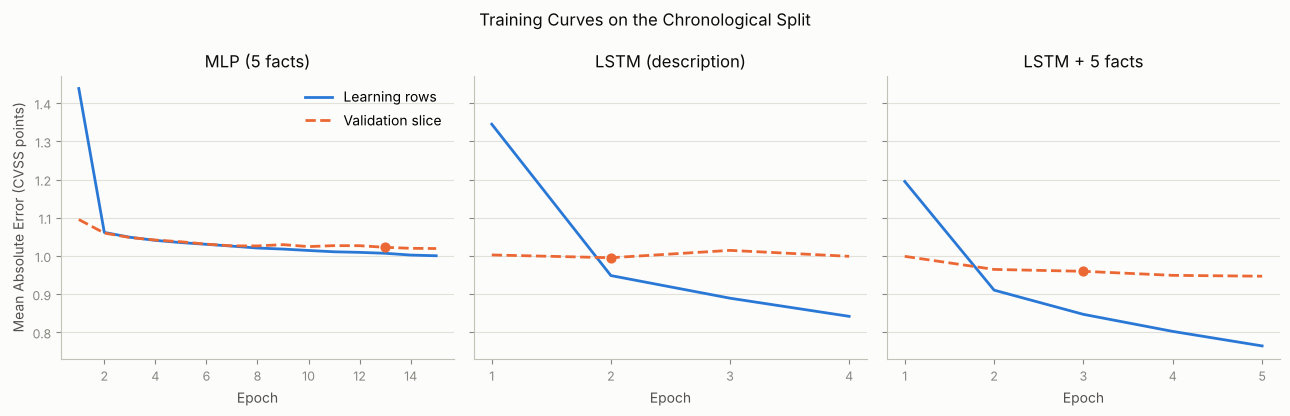

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharey=True)
for ax, key, title in zip(axes, ["MLP", "LSTM", "LSTM + facts"],
                          ["MLP (5 facts)", "LSTM (description)", "LSTM + 5 facts"]):
    h = histories[("B: chronological", key)]
    ep = np.arange(1, len(h["mae"]) + 1)
    ax.plot(ep, h["mae"], color=CAT[0], linewidth=2, label="Learning rows")
    ax.plot(ep, h["val_mae"], color=CAT[1], linewidth=2, linestyle="--", label="Validation slice")
    best = int(np.argmin(h["val_loss"]))
    ax.scatter([ep[best]], [h["val_mae"][best]], color=CAT[1], zorder=3, s=40)
    ax.set_title(title); ax.set_xlabel("Epoch")
    ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
    style_ax(ax)
axes[0].set_ylabel("Mean Absolute Error (CVSS points)")
axes[0].legend(frameon=False)
fig.suptitle("Training Curves on the Chronological Split", color=INK_PRIMARY)
fig.savefig("figures/training_curves.png", dpi=200, facecolor=SURFACE, bbox_inches="tight")
plt.show()

### 3.8 Severity bands: precision, recall, and the CRITICAL problem

An average error can hide poor performance on a small but important group. Here each
model's predicted score is converted to a severity band and compared with the true band:

- **Confusion matrix:** rows are the true band, columns the predicted band. Each row is
  shown as percentages, so the diagonal is the share of each band classified correctly.
- **Precision** (for a band): of the CVEs predicted in that band, how many truly are.
- **Recall** (for a band): of the CVEs truly in that band, how many were predicted in it.
- **F1:** a single score that balances precision and recall (their harmonic mean).

In [21]:
B = "B: chronological"
true_band = severity_band(pd.Series(y_te_B))
band_of = lambda p: severity_band(pd.Series(np.clip(p, 0, 10)))   # clip to the 0-10 scale

rows = []
for name in ["Ridge (MP3)", "SVR (MP3, 30k sample)", "Neural network (MLP), 5 facts",
             "LSTM, description text", "LSTM + 5 facts (combined)"]:
    p, r, f, n = precision_recall_fscore_support(true_band, band_of(preds[(B, name)]),
                                                 labels=SEVERITY_ORDER, zero_division=0)
    for sev, pp_, rr, ff, nn in zip(SEVERITY_ORDER, p, r, f, n):
        rows.append({"Model": name, "Band": sev, "Precision": pp_, "Recall": rr, "F1": ff,
                     "True CVEs": nn})
band_df = pd.DataFrame(rows)
print("Per-band precision / recall / F1 on the chronological test set:")
print(band_df.pivot(index="Model", columns="Band", values="Recall")[SEVERITY_ORDER]
      .round(3).to_string(), "\n  ^ recall by band\n")
print(band_df.pivot(index="Model", columns="Band", values="F1")[SEVERITY_ORDER]
      .round(3).to_string(), "\n  ^ F1 by band")
crit = band_df[band_df["Band"] == "CRITICAL"].set_index("Model")[["Precision", "Recall", "F1"]]
print("\nCRITICAL band only:\n", crit.round(3).to_string())
band_df.round(4).to_csv("figures/mp4_band_metrics.csv", index=False)

Per-band precision / recall / F1 on the chronological test set:
Band                             LOW  MEDIUM   HIGH  CRITICAL
Model                                                        
LSTM + 5 facts (combined)      0.003   0.780  0.577     0.152
LSTM, description text         0.000   0.762  0.573     0.153
Neural network (MLP), 5 facts  0.000   0.714  0.558     0.030
Ridge (MP3)                    0.001   0.705  0.562     0.032
SVR (MP3, 30k sample)          0.000   0.710  0.580     0.073 
  ^ recall by band

Band                             LOW  MEDIUM   HIGH  CRITICAL
Model                                                        
LSTM + 5 facts (combined)      0.006   0.675  0.580     0.231
LSTM, description text         0.000   0.664  0.572     0.233
Neural network (MLP), 5 facts  0.000   0.614  0.546     0.054
Ridge (MP3)                    0.002   0.611  0.544     0.060
SVR (MP3, 30k sample)          0.000   0.630  0.565     0.113 
  ^ F1 by band

CRITICAL band only:
          

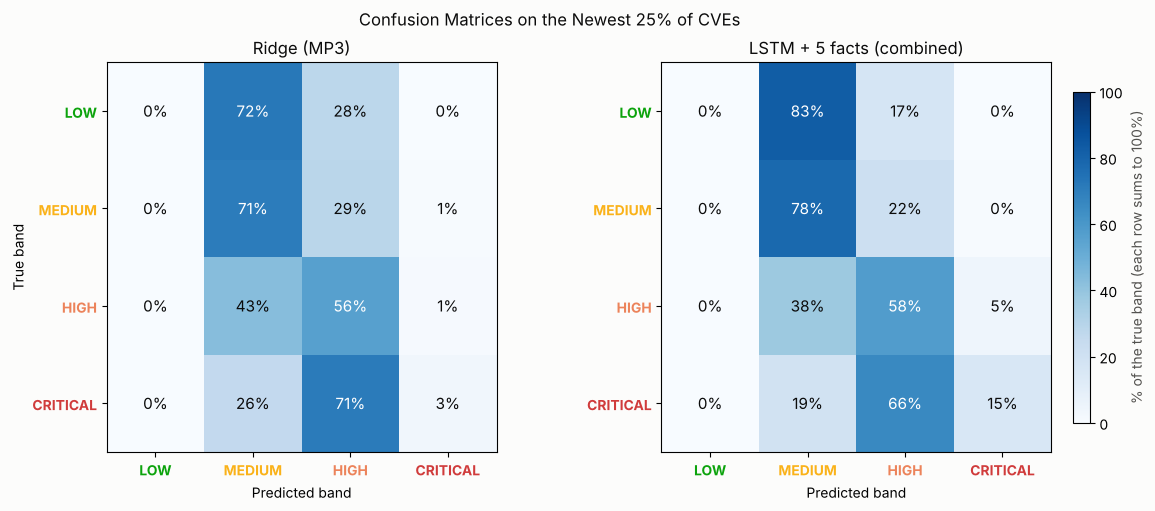

In [22]:
# Chart 4: row-normalized confusion matrices, Ridge (MP3) vs. the combined LSTM model.
fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")
for ax, name, title in [(axes[0], "Ridge (MP3)", "Ridge (MP3)"),
                        (axes[1], "LSTM + 5 facts (combined)", "LSTM + 5 facts (combined)")]:
    cm = confusion_matrix(true_band, band_of(preds[(B, name)]), labels=SEVERITY_ORDER)
    cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100
    im = ax.imshow(cm_pct, cmap="Blues", vmin=0, vmax=100)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f"{cm_pct[i, j]:.0f}%", ha="center", va="center", fontsize=11,
                    color="white" if cm_pct[i, j] > 55 else INK_PRIMARY)
    ax.set_xticks(range(4)); ax.set_xticklabels(SEVERITY_ORDER)
    ax.set_yticks(range(4)); ax.set_yticklabels(SEVERITY_ORDER)
    ax.set_xlabel("Predicted band"); ax.set_title(title, color=INK_PRIMARY)
    for t, sev in zip(list(ax.get_xticklabels()) + list(ax.get_yticklabels()), SEVERITY_ORDER * 2):
        t.set_color(STATUS[sev]); t.set_fontweight("bold")
axes[0].set_ylabel("True band")
cb = fig.colorbar(im, ax=axes, shrink=0.85, pad=0.02)
cb.set_label("% of the true band (each row sums to 100%)", color=INK_SECONDARY)
fig.suptitle("Confusion Matrices on the Newest 25% of CVEs", color=INK_PRIMARY)
fig.set_facecolor(SURFACE)
fig.savefig("figures/confusion_matrices.png", dpi=200, facecolor=SURFACE, bbox_inches="tight")
plt.show()

Average signed error by true band (CVSS points, above 0 = guessed too high):
          Ridge (MP3)  LSTM + 5 facts
band                                 
LOW              3.37            2.93
MEDIUM           0.93            0.70
HIGH            -0.73           -0.58
CRITICAL        -2.13           -1.73


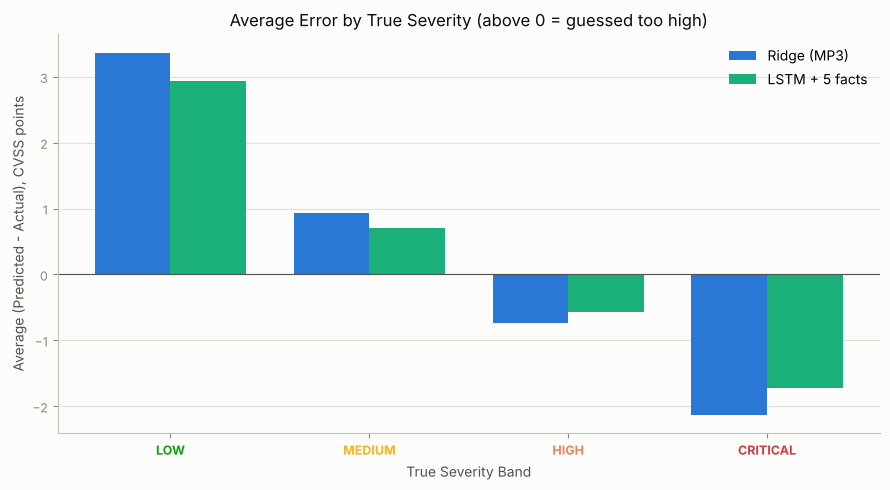

In [23]:
# Chart 5: average signed error (predicted - actual) by true band, same chart as Micro-Project 3.
err = pd.DataFrame({"Ridge (MP3)": preds[(B, "Ridge (MP3)")] - y_te_B,
                    "LSTM + 5 facts": preds[(B, "LSTM + 5 facts (combined)")] - y_te_B,
                    "band": true_band.values}).groupby("band", observed=True).mean().reindex(SEVERITY_ORDER)
print("Average signed error by true band (CVSS points, above 0 = guessed too high):")
print(err.round(2).to_string())

x = np.arange(4); w = 0.38
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(x - w / 2, err["Ridge (MP3)"], w, color=CAT[0], label="Ridge (MP3)")
ax.bar(x + w / 2, err["LSTM + 5 facts"], w, color=CAT[2], label="LSTM + 5 facts")
ax.axhline(0, color=INK_SECONDARY, linewidth=0.8)
ax.set_xticks(x); ax.set_xticklabels(SEVERITY_ORDER)
ax.set_title("Average Error by True Severity (above 0 = guessed too high)")
ax.set_xlabel("True Severity Band"); ax.set_ylabel("Average (Predicted - Actual), CVSS points")
ax.legend(frameon=False)
style_ax(ax)
for t, sev in zip(ax.get_xticklabels(), SEVERITY_ORDER):   # color labels after styling
    t.set_color(STATUS[sev]); t.set_fontweight("bold")
fig.savefig("figures/error_by_band.png", dpi=200, facecolor=SURFACE)
plt.show()

### 3.9 Day-one test: what if the weakness type is not known yet?

Micro-Project 3 found that 99.6% of CVEs still waiting for a score have no weakness type
(CWE). To measure what that does to each model, every chronological test CVE is graded a
second time with its weakness type replaced by `"Unknown"`, exactly how a not-yet-analyzed
CVE looks. Nothing is retrained. The description-only LSTM does not use the weakness type,
so its result cannot change.

                               MAE with CWE  MAE, CWE unknown  R2 with CWE  R2, CWE unknown  CRITICAL flagged (pred >= 7), CWE unknown
Model                                                                                                                                 
Ridge (MP3)                           1.274             1.499        0.117           -0.135                                      0.063
Neural network (MLP), 5 facts         1.259             1.513        0.120           -0.161                                      0.060
LSTM, description text                1.146             1.146        0.251            0.251                                      0.805
LSTM + 5 facts (combined)             1.114             1.205        0.289            0.212                                      0.689

Baseline MAE for reference: 1.402


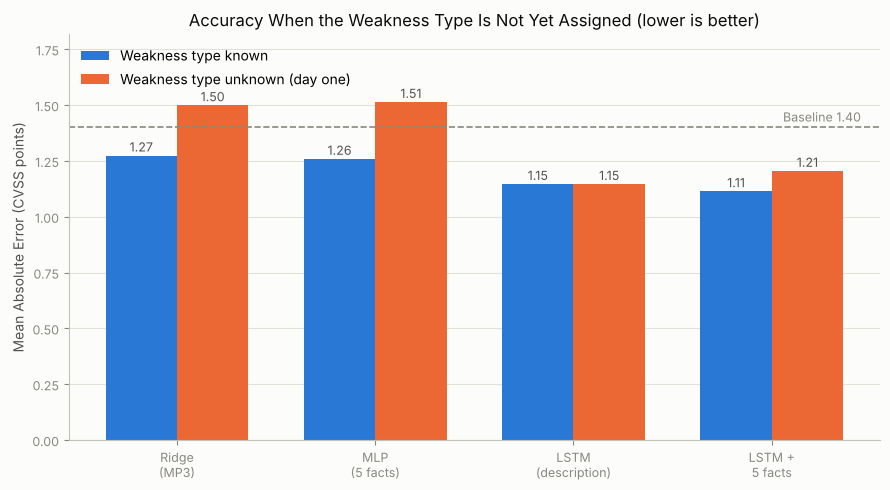

In [24]:
X_day1 = X_all.loc[idx_test_B].copy()
X_day1["cwe_id"] = "Unknown"                     # weakness type not assigned yet
T_day1 = prep_B.transform(X_day1).toarray().astype("float32")

day1 = {
    "Ridge (MP3)": ridge_B.predict(X_day1),
    "Neural network (MLP), 5 facts": mlp_B.predict(T_day1, batch_size=4096, verbose=0).ravel(),
    "LSTM, description text": preds[(B, "LSTM, description text")],   # does not use CWE
    "LSTM + 5 facts (combined)": combined.predict([S_te, T_day1], batch_size=2048, verbose=0).ravel(),
}
day1_rows = []
for name, p in day1.items():
    day1_rows.append({"Model": name,
                      "MAE with CWE": mean_absolute_error(y_te_B, preds[(B, name)]),
                      "MAE, CWE unknown": mean_absolute_error(y_te_B, p),
                      "R2 with CWE": r2_score(y_te_B, preds[(B, name)]),
                      "R2, CWE unknown": r2_score(y_te_B, p),
                      "CRITICAL flagged (pred >= 7), CWE unknown": (p[y_te_B >= 9] >= 7).mean()})
day1_df = pd.DataFrame(day1_rows).set_index("Model")
print(day1_df.round(3).to_string())
print(f"\nBaseline MAE for reference: {base_mae:.3f}")
day1_df.round(4).to_csv("figures/mp4_day_one.csv")

# Chart 6: MAE with and without the weakness type
lab = ["Ridge\n(MP3)", "MLP\n(5 facts)", "LSTM\n(description)", "LSTM +\n5 facts"]
x = np.arange(4); w = 0.36
fig, ax = plt.subplots(figsize=(9, 5))
for k, (col, color, l) in enumerate([("MAE with CWE", CAT[0], "Weakness type known"),
                                     ("MAE, CWE unknown", CAT[1], "Weakness type unknown (day one)")]):
    v = day1_df[col].values
    bb = ax.bar(x + (k - 0.5) * w, v, w, color=color, label=l)
    for b, val in zip(bb, v):
        ax.annotate(f"{val:.2f}", (b.get_x() + b.get_width() / 2, val), xytext=(0, 3),
                    textcoords="offset points", ha="center", fontsize=9, color=INK_SECONDARY)
ax.axhline(base_mae, color=INK_MUTED, linestyle="--", linewidth=1.2)
ax.annotate(f"Baseline {base_mae:.2f}", (3.45, base_mae), xytext=(0, 4), textcoords="offset points",
            ha="right", fontsize=9, color=INK_MUTED)
ax.set_xticks(x); ax.set_xticklabels(lab)
ax.set_ylabel("Mean Absolute Error (CVSS points)")
ax.set_title("Accuracy When the Weakness Type Is Not Yet Assigned (lower is better)")
ax.set_ylim(0, day1_df[["MAE with CWE", "MAE, CWE unknown"]].values.max() * 1.2)
ax.legend(frameon=False, loc="upper left")
style_ax(ax)
fig.savefig("figures/day_one_test.png", dpi=200, facecolor=SURFACE)
plt.show()

## Step 4: Report

**Summary of results** (chronological split: trained on older CVEs, graded on the newest
25%, with Micro-Project 3's baseline and metrics). Exact values are printed in section 3.7.

- **Testing on newer CVEs is much harder than testing on a random sample.** Ridge
  regression, Micro-Project 3's day-to-day model, reproduces its Micro-Project 3 result on
  the random split (R-squared about 0.31) but falls to about 0.12 on newer CVEs. Its
  training-vs-test gap grows from almost zero to more than 0.2. Micro-Project 3's random
  test overstated how well the models would work on new CVEs.
- **Added complexity alone did not help.** The feed-forward neural network (MLP), given the
  same five facts, beat Ridge on the random split but only matched it on newer CVEs. Its
  extra flexibility mostly learned vendor and product combinations that had already been
  seen.
- **Reading the description did help.** The LSTM that reads only the description had a
  clearly lower error than Ridge, SVR, and the MLP, and roughly doubled the share of
  variation explained compared with Ridge. Combining the description with the five facts
  was the most accurate model overall.
- **The text models keep working on day one.** With the weakness type removed, Ridge and
  the MLP become *worse* than the baseline (negative R-squared), while the LSTM models stay
  well ahead of it. On the CVEs still awaiting a score, Ridge gives nearly every CVE the
  same score, while the description LSTM spreads them out enough to rank.
- **CRITICAL is still the hardest band.** Every model still pulls predictions toward the
  middle and under-rates truly CRITICAL CVEs. The text models are better at it than Ridge,
  but most truly CRITICAL CVEs are still predicted as HIGH rather than CRITICAL (section
  3.8). The training curves and training-vs-test gap also show the LSTM models fit their
  training data more tightly than new data, which early stopping limits but does not remove.

**Connection to the hypothesis.** The hypothesis is **supported.** On newly published CVEs,
the LSTM reading the description beat every Micro-Project 3 model on the same baseline and
metrics, and it did not depend on the weakness type. The control result matters just as
much: a neural network that only received the same facts did not improve on Ridge, so the
gain comes from the new information (the description), not from deep learning by itself.
The limit is that roughly 70% of the variation in severity on new CVEs is still
unexplained, so individual predictions remain rough.

## Step 5: Act

### 5.1 The triage test from Micro-Project 3, on newer CVEs

The same practical question as Micro-Project 3: if a team flags every new CVE with a
predicted score of 7.0 or above (HIGH or CRITICAL) for early review, how well does that
work? And if the team can only review the top quarter of the queue first, how many truly
CRITICAL CVEs are in it?

In [25]:
actual_high = y_te_B >= 7.0
critical = y_te_B >= 9.0
triage = []
for name in ["Ridge (MP3)", "LSTM, description text", "LSTM + 5 facts (combined)"]:
    p = preds[(B, name)]
    flagged = p >= 7.0
    top_q = p >= np.quantile(p, 0.75)
    triage.append({"Model": name,
                   "Flagged share": flagged.mean(),
                   "Flagged that are truly HIGH/CRITICAL": actual_high[flagged].mean(),
                   "CRITICAL caught by the flag": flagged[critical].mean(),
                   "CRITICAL in top 25% of queue": top_q[critical].mean()})
triage_df = pd.DataFrame(triage).set_index("Model")
print(f"Newest-25% test CVEs: {len(y_te_B):,} | truly HIGH or CRITICAL: {actual_high.mean():.1%} "
      f"| truly CRITICAL: {critical.mean():.1%}")
print(triage_df.round(3).to_string())
triage_df.round(4).to_csv("figures/mp4_triage.csv")

Newest-25% test CVEs: 74,685 | truly HIGH or CRITICAL: 56.2% | truly CRITICAL: 13.0%
                           Flagged share  Flagged that are truly HIGH/CRITICAL  CRITICAL caught by the flag  CRITICAL in top 25% of queue
Model                                                                                                                                    
Ridge (MP3)                        0.440                                 0.747                        0.720                         0.492
LSTM, description text             0.463                                 0.789                        0.805                         0.593
LSTM + 5 facts (combined)          0.456                                 0.804                        0.802                         0.598


### 5.2 A separate "possible CRITICAL" cutoff

Because predictions are pulled toward the middle, a predicted score of 9.0 or above is
rare, so the CRITICAL band (recall in 3.8) catches only a small share of truly CRITICAL
CVEs. A team does not have to use 9.0 as its cutoff. The chart below shows, for the
combined model, what happens if a CVE is marked "possible CRITICAL" at a lower predicted
score: more truly CRITICAL CVEs are caught (recall rises), but more of the marked CVEs turn
out not to be CRITICAL (precision falls).

                    Model  Cutoff  CRITICAL recall  Precision  Share marked
LSTM + 5 facts (combined)    7.00            0.802      0.228         0.456
LSTM + 5 facts (combined)    7.25            0.751      0.250         0.391
LSTM + 5 facts (combined)    7.50            0.688      0.274         0.326
LSTM + 5 facts (combined)    7.75            0.618      0.302         0.266
LSTM + 5 facts (combined)    8.00            0.536      0.337         0.207
LSTM + 5 facts (combined)    8.25            0.438      0.371         0.153
LSTM + 5 facts (combined)    8.50            0.334      0.413         0.105
LSTM + 5 facts (combined)    8.75            0.232      0.448         0.067
LSTM + 5 facts (combined)    9.00            0.129      0.476         0.035


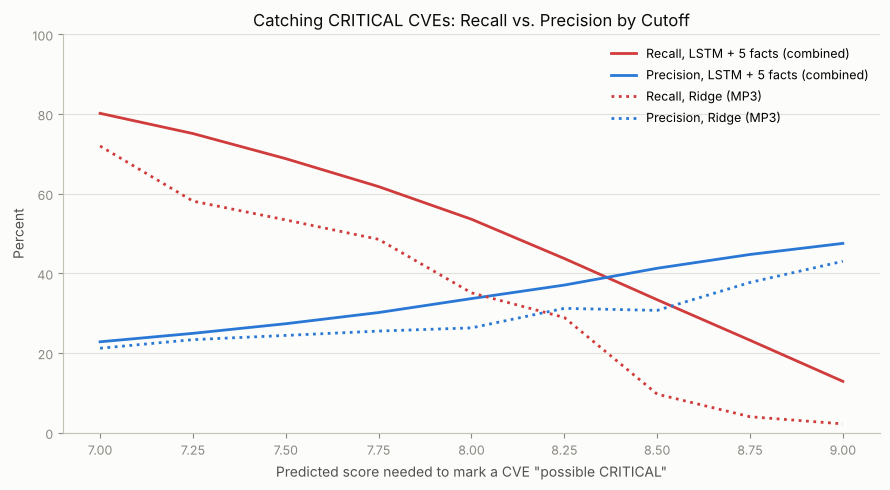

In [26]:
cutoffs = np.round(np.arange(7.0, 9.01, 0.25), 2)
trade = []
for name in ["Ridge (MP3)", "LSTM + 5 facts (combined)"]:
    p = preds[(B, name)]
    for c in cutoffs:
        marked = p >= c
        trade.append({"Model": name, "Cutoff": c,
                      "CRITICAL recall": marked[critical].mean(),
                      "Precision": critical[marked].mean() if marked.any() else np.nan,
                      "Share marked": marked.mean()})
trade_df = pd.DataFrame(trade)
print(trade_df[trade_df["Model"] == "LSTM + 5 facts (combined)"].round(3).to_string(index=False))
trade_df.round(4).to_csv("figures/mp4_critical_cutoffs.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 5))
for name, ls in [("LSTM + 5 facts (combined)", "-"), ("Ridge (MP3)", ":")]:
    t = trade_df[trade_df["Model"] == name]
    ax.plot(t["Cutoff"], t["CRITICAL recall"] * 100, color=STATUS["CRITICAL"], linestyle=ls,
            linewidth=2, label=f"Recall, {name}")
    ax.plot(t["Cutoff"], t["Precision"] * 100, color=CAT[0], linestyle=ls, linewidth=2,
            label=f"Precision, {name}")
ax.set_xlabel('Predicted score needed to mark a CVE "possible CRITICAL"')
ax.set_ylabel("Percent")
ax.set_title("Catching CRITICAL CVEs: Recall vs. Precision by Cutoff")
ax.set_ylim(0, 100)
ax.legend(frameon=False, fontsize=9, loc="upper right")
style_ax(ax)
fig.savefig("figures/critical_cutoffs.png", dpi=200, facecolor=SURFACE)
plt.show()

### 5.3 Applying the models to CVEs that have no score yet

The main cleaned dataset keeps the CVEs NVD has not scored yet. In Micro-Project 3, Ridge
gave 99.7% of them the same band (HIGH), which is not a useful ranking, because nearly all of
them have no weakness type. All of them do have a description. The models trained on the chronological
split are applied to them below.

Unscored CVEs: 3,378 | with no weakness type: 99.5%

Predicted band, % of unscored CVEs:
          Ridge (MP3)  LSTM (description)  LSTM + 5 facts
LOW               0.0                 0.0             0.0
MEDIUM           99.9                92.9            97.8
HIGH              0.1                 7.1             2.2
CRITICAL          0.0                 0.0             0.0

Spread of predicted scores (standard deviation, CVSS points):
Ridge (MP3)           0.13
LSTM (description)    0.63
LSTM + 5 facts        0.39


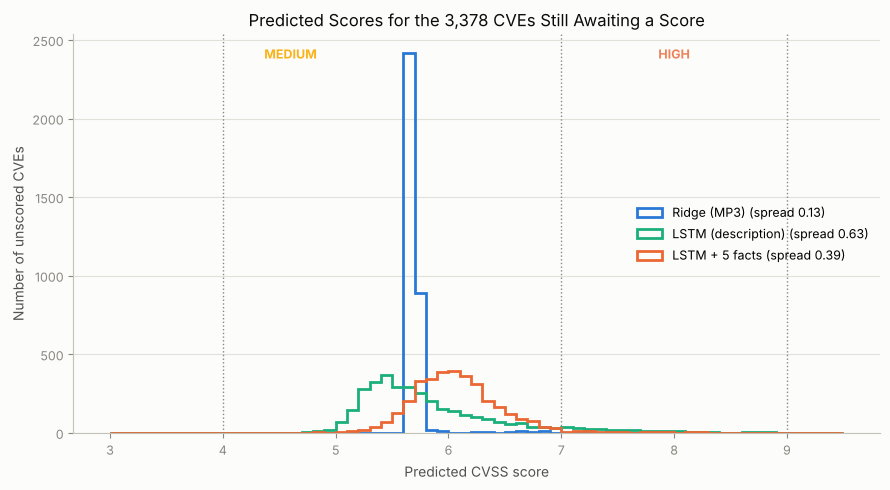


Top 10 unscored CVEs to review first (combined model):
         cve_id                                    primary_vendor  LSTM + 5 facts
 CVE-2026-78797                                           Unknown            8.38
 CVE-2026-80800                                             Linux            8.24
 CVE-2026-78835                                           Unknown            8.22
 CVE-2026-71575                        Apache Software Foundation            8.18
  CVE-2023-4674 Yaztek Software Technologies and Computer Systems            8.10
 CVE-2024-54982                                           Unknown            8.06
 CVE-2025-71197                                             Linux            7.95
 CVE-2026-80799                                             Linux            7.94
CVE-2026-106327                                            Google            7.87
CVE-2026-107938                        Apache Software Foundation            7.82


In [27]:
pending = df[~df["has_any_score"]].copy()
for col in CAT_FEATURES:
    pending[col] = pending[col].fillna("Unknown")
pending["text"] = pending["description_en"].map(clean_description)
S_pend = vec_B(pending["text"].values).numpy()
T_pend = prep_B.transform(pending[CAT_FEATURES + NUM_FEATURES]).toarray().astype("float32")

pending["Ridge (MP3)"] = ridge_B.predict(pending[CAT_FEATURES + NUM_FEATURES]).clip(0, 10)
pending["LSTM (description)"] = lstm.predict(S_pend, batch_size=2048, verbose=0).ravel().clip(0, 10)
pending["LSTM + 5 facts"] = combined.predict([S_pend, T_pend], batch_size=2048, verbose=0).ravel().clip(0, 10)

print(f"Unscored CVEs: {len(pending):,} | with no weakness type: {(pending['cwe_id'] == 'Unknown').mean():.1%}")
pend_cols = ["Ridge (MP3)", "LSTM (description)", "LSTM + 5 facts"]
bands_tbl = pd.DataFrame({c: severity_band(pending[c]).value_counts(normalize=True)
                          for c in pend_cols}).reindex(SEVERITY_ORDER).mul(100).round(1)
print("\nPredicted band, % of unscored CVEs:")
print(bands_tbl.to_string())
print("\nSpread of predicted scores (standard deviation, CVSS points):")
print(pending[pend_cols].std().round(2).to_string())

# Chart 8: distribution of predicted scores for the unscored CVEs. A model that gives every
# CVE nearly the same score cannot rank them; a wider spread means it can tell them apart.
fig, ax = plt.subplots(figsize=(9, 5))
bins = np.arange(3.0, 9.6, 0.1)
for c, color in zip(pend_cols, [CAT[0], CAT[2], CAT[1]]):
    ax.hist(pending[c], bins=bins, histtype="step", linewidth=2, color=color,
            label=f"{c} (spread {pending[c].std():.2f})")
for edge in (4.0, 7.0, 9.0):                    # severity band boundaries
    ax.axvline(edge, color=INK_MUTED, linestyle=":", linewidth=1)
for xt, lab in [(4.6, "MEDIUM"), (8.0, "HIGH")]:
    ax.text(xt, ax.get_ylim()[1] * 0.97, lab, ha="center", va="top", fontsize=9,
            color=STATUS[lab], fontweight="bold")
ax.set_xlabel("Predicted CVSS score"); ax.set_ylabel("Number of unscored CVEs")
ax.set_title(f"Predicted Scores for the {len(pending):,} CVEs Still Awaiting a Score")
ax.legend(frameon=False, loc="center right", fontsize=9)
style_ax(ax)
fig.savefig("figures/unscored_scores.png", dpi=200, facecolor=SURFACE, bbox_inches="tight")
plt.show()

queue = pending.sort_values("LSTM + 5 facts", ascending=False)
print("\nTop 10 unscored CVEs to review first (combined model):")
print(queue[["cve_id", "primary_vendor", "LSTM + 5 facts"]].head(10).round(2).to_string(index=False))
queue[["cve_id", "published_date", "primary_vendor", "primary_product", "cwe_id"]
      + pend_cols].round({c: 2 for c in pend_cols}).to_csv("figures/unscored_review_queue_mp4.csv", index=False)

**Reading this result:** Ridge gives almost every unscored CVE nearly the same score (a
spread of only about a tenth of a point), so it cannot rank them: its most informative
input, the weakness type, is missing. The description-based LSTM spreads the same CVEs
about five times more widely, so a review queue sorted by its score actually separates
them. Most unscored CVEs still land in the MEDIUM range under every model (about 99% of them are
Linux kernel fixes, which usually score MEDIUM), so the useful output here is the
*ordering*, with the highest-scored CVEs reviewed first. There is no official score yet to
check these individual predictions against; the evidence that the ordering is meaningful
comes from the day-one test in section 3.9, where the same models were graded on known
scores with the weakness type removed.

### 5.4 Recommendations

1. **Use the combined LSTM model as the first-pass triage queue for newly published CVEs.**
   It was the most accurate model on CVEs newer than anything it trained on, and it still
   ranks CVEs whose weakness type has not been assigned. The official CVSS score replaces
   the estimate once it arrives.
2. **Use the description-only LSTM when the facts are missing.** It needs nothing but the
   text, so it can score a CVE the moment it is published.
3. **Do not use Ridge or the MLP on CVEs without a weakness type.** With the weakness type
   unknown, both were no better than guessing the average (section 3.9).
4. **Mark "possible CRITICAL" with a lower cutoff than 9.0.** Predicted scores rarely reach
   9.0: at that cutoff the combined model catches only about 13% of truly CRITICAL CVEs. At
   8.0 it catches about 54% while marking about a fifth of all new CVEs, and at 7.5 about
   69% while marking about a third (section 5.2). The team picks the cutoff based on how
   many extra reviews it can afford.
5. **Keep fast-tracking code-execution weakness types** (CWE-502, CWE-434, CWE-78, CWE-94,
   CWE-89) whenever a weakness type is known, as in Micro-Project 3, because every model
   still under-rates CRITICAL CVEs.
6. **Judge any severity model on newer CVEs, not a random sample.** The random split made
   every model look better than it is on new CVEs. Retrain regularly on the most recent
   data, since new vendors, products, and wording keep appearing.

### 5.5 Limitations

- About 70% of the variation in severity on new CVEs is still unexplained, so individual
  predictions can be off by two points or more.
- The LSTM models fit their training data noticeably better than new data (training curves
  and training-vs-test gap). Early stopping keeps this in check but does not remove it.
- Some vendors describe the attack conditions in words in their descriptions (for example
  "unauthenticated attacker with network access"). That information is genuinely available
  at publication, but it makes those vendors' CVEs easier to score than others.
- The neural networks learned from 90% of the training rows (10% was held back for early
  stopping), while Ridge used all of them; this slightly favors Ridge, so the comparison is
  conservative.
- The LSTM is far slower to train than Ridge (minutes per epoch versus seconds in total),
  and its reasoning cannot be read off as simple weights.
- Results come from one chronological cutoff. Neural network training has some randomness;
  the seed is fixed so the results reproduce, but a different seed would move the numbers
  slightly.